<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-scientific-discovery/blob/main/notebooks/lecture-09/tree-foundations.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

In [ ]:
#| code-fold: true
#| code-summary: Load supporting course files when running in Colab
from pathlib import Path
from urllib.request import urlretrieve
for name in ['data/galaxy10_measurements.csv']:
    target = Path(name)
    if not target.exists():
        target.parent.mkdir(parents=True, exist_ok=True)
        urlretrieve('https://raw.githubusercontent.com/MarcinPlodzien/deep-learning-for-scientific-discovery/main/notebooks/lecture-09/' + name, target)

# Decision trees with scikit-learn

We learn a question from six labelled observations, inspect the fitted tree and predict a new observation. We then compare a tree, forest and neural network on flower classification and numerical diabetes progression. No learning algorithm is implemented here. The arithmetic explains the loss minimized by the library.

Use the supplied local files and run cells in order. Follow this notebook with the MNIST notebook for classification directly from pixels, and the galaxy notebooks for a scientific image investigation. The longer tabular comparison develops validation, model diagnostics and importance.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.datasets import load_iris, load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.metrics import balanced_accuracy_score, root_mean_squared_error
from sklearn.dummy import DummyClassifier, DummyRegressor
from threadpoolctl import threadpool_limits
threadpool_limits(limits=2)
SEED = 1975

## One fitted question

The feature is a measured length. Labels A and B are coded as 0 and 1. The six labels have proportions $(1/2,1/2)$ and Gini impurity $1-(1/2)^2-(1/2)^2=1/2$. A stump is a tree with depth one.

Before running the cell, compare the groups formed by a threshold between lengths 3 and 4. State the class probability and hard prediction for a new length 4.2.

|--- length <= 3.50
|   |--- class: 0
|--- length >  3.50
|   |--- class: 1

Class [1] probabilities [[0. 1.]]


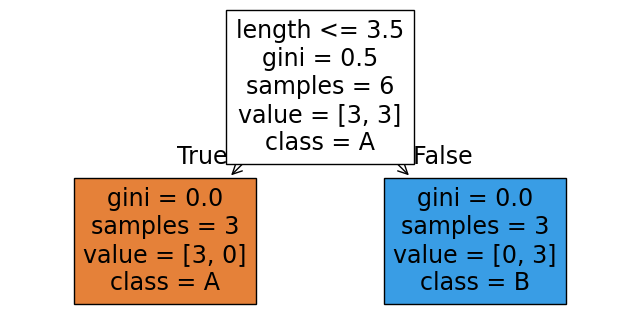

In [2]:
length = np.array([1., 2., 3., 4., 5., 6.]).reshape(-1, 1)
label = np.array([0, 0, 0, 1, 1, 1])
stump = DecisionTreeClassifier(max_depth=1, random_state=SEED)
stump.fit(length, label)
print(export_text(stump, feature_names=["length"]))
print("Class", stump.predict([[4.2]]), "probabilities", stump.predict_proba([[4.2]]))
fig, ax = plt.subplots(figsize=(8, 4))
plot_tree(stump, feature_names=["length"], class_names=["A", "B"], filled=True, ax=ax)
plt.show()

The threshold is 3.5. Both children are pure, the weighted child impurity is zero, and the gain is 0.5. The new observation reaches class B with fitting frequency one in its leaf. That frequency alone supplies no guarantee of correctness on another population.

## A probability change without a class change

Eight labels are A and two are B. A proposed question gives counts $(5,0)$ and $(3,2)$. Calculate the parent and weighted child Gini impurities and count majority-class errors before and after splitting.

<details><summary>Feedback</summary>

The parent impurity is 0.32. The weighted child impurity is $0.5(0)+0.5(0.48)=0.24$, giving a gain of 0.08. Both children predict A, so the two B labels remain hard-decision errors. The class probabilities become more informative on the fitting observations.

</details>

## A numerical target

At inputs 1, 2 and 3 the responses are 1, 2 and 6. Compare candidate thresholds 1.5 and 2.5 by adding the squared deviations from each child mean. Then fit the estimator and predict at 2.2.

In [3]:
regressor = DecisionTreeRegressor(max_depth=1, random_state=SEED)
regressor.fit([[1.], [2.], [3.]], [1., 2., 6.])
print(export_text(regressor, feature_names=["input"]))
print("Prediction at 2.2", regressor.predict([[2.2]])[0])

|--- input <= 2.50
|   |--- value: [1.50]
|--- input >  2.50
|   |--- value: [6.00]

Prediction at 2.2 1.5


## The same workflow for three model families

For each task we set aside test observations, then divide the rest into fitting and validation observations. The classification split is stratified to retain each species. We fix two small candidates for each family before inspecting results. Fitting learns each candidate, validation chooses one per family and test assesses the frozen choices. Ties go to the earlier listed candidate. We keep the fitting set fixed after selection so that the procedure is easy to follow.

Input scaling belongs inside the network pipeline. For regression, `TransformedTargetRegressor` also scales the target using fitting statistics and converts predictions back to score units. A dummy estimator supplies a baseline.

In [4]:
iris = load_iris()
diabetes = load_diabetes(scaled=False)
tasks = {"Iris classification": (iris.data, iris.target, True),
         "Diabetes regression": (diabetes.data[:, [2, 3]], diabetes.target, False)}
data = {}
for task, (X, y, classification) in tasks.items():
    pool, test = train_test_split(np.arange(len(y)), test_size=.2, random_state=SEED,
                                 stratify=y if classification else None)
    fit, val = train_test_split(pool, test_size=.25, random_state=SEED,
                               stratify=y[pool] if classification else None)
    data[task] = dict(X=X, y=y, classification=classification, fit=fit, val=val, test=test)
    print(task, "fitting/validation/test", len(fit), len(val), len(test))

Iris classification fitting/validation/test 90 30 30
Diabetes regression fitting/validation/test 264 89 89


In [5]:
candidates = {}
for task, d in data.items():
    classification = d["classification"]
    Tree = DecisionTreeClassifier if classification else DecisionTreeRegressor
    Forest = RandomForestClassifier if classification else RandomForestRegressor
    Network = MLPClassifier if classification else MLPRegressor
    networks = []
    for alpha in [.1, 1.]:
        network = make_pipeline(StandardScaler(), Network(hidden_layer_sizes=(8,), activation="tanh",
                    solver="lbfgs", alpha=alpha, max_iter=5000, random_state=SEED))
        networks.append(network if classification else TransformedTargetRegressor(
                        regressor=network, transformer=StandardScaler()))
    candidates[task] = {
        "Tree": [Tree(max_depth=depth, min_samples_leaf=5, random_state=SEED) for depth in [2, 4]],
        "Forest": [Forest(n_estimators=100, min_samples_leaf=5, max_features=m,
                         random_state=SEED, n_jobs=2) for m in ["sqrt", 1.]],
        "Network": networks}

## Validation and a frozen choice

Predict which family may need input scaling and which setting controls explanation length. Run the validation comparison, then record the selected candidates before evaluating the test set. The regression score is negative RMSE so that a larger validation score is preferred for every task.

In [6]:
selected, validation_rows = {}, []
for task, d in data.items():
    X, y, fit, val = d["X"], d["y"], d["fit"], d["val"]
    selected[task] = {}
    for family, models in candidates[task].items():
        scores = []
        for i, model in enumerate(models):
            model.fit(X[fit], y[fit])
            prediction = model.predict(X[val])
            score = (balanced_accuracy_score(y[val], prediction) if d["classification"]
                     else -root_mean_squared_error(y[val], prediction))
            scores.append(score)
            validation_rows.append(dict(task=task, family=family, candidate=i, validation_score=score))
        selected[task][family] = models[int(np.argmax(scores))]
display(pd.DataFrame(validation_rows))

,task,family,candidate,validation_score
0,Iris classification,Tree,0,0.966667
1,Iris classification,Tree,1,0.966667
2,Iris classification,Forest,0,0.966667
3,Iris classification,Forest,1,0.966667
4,Iris classification,Network,0,0.966667
5,Iris classification,Network,1,0.900000
6,Diabetes regression,Tree,0,-63.866636
7,Diabetes regression,Tree,1,-62.396579
8,Diabetes regression,Forest,0,-62.064303
9,Diabetes regression,Forest,1,-62.882528


## Test evaluation

All choices are fixed. A new model choice after viewing this table would require new evaluation data. The examples use small candidate sets and one data split, so they illustrate a procedure without establishing a general ranking of algorithms.

In [7]:
test_rows = []
for task, d in data.items():
    X, y, fit, test = d["X"], d["y"], d["fit"], d["test"]
    baseline = DummyClassifier(strategy="most_frequent") if d["classification"] else DummyRegressor(strategy="mean")
    baseline.fit(X[fit], y[fit])
    for family, model in {"Baseline": baseline, **selected[task]}.items():
        prediction = model.predict(X[test])
        metric = (balanced_accuracy_score(y[test], prediction) if d["classification"]
                  else root_mean_squared_error(y[test], prediction))
        test_rows.append(dict(task=task, family=family, metric="balanced accuracy" if d["classification"] else "RMSE", value=metric))
display(pd.DataFrame(test_rows))

,task,family,metric,value
0,Iris classification,Baseline,balanced accuracy,0.333333
1,Iris classification,Tree,balanced accuracy,0.900000
2,Iris classification,Forest,balanced accuracy,0.933333
3,Iris classification,Network,balanced accuracy,0.933333
4,Diabetes regression,Baseline,RMSE,79.183729
5,Diabetes regression,Tree,RMSE,71.557479
6,Diabetes regression,Forest,RMSE,70.166678
7,Diabetes regression,Network,RMSE,67.500672


## Galaxy measurements without an image download

The supplied CSV contains measurements of the course images and their fixed split. It contains raw feature values, so imputation is fitted only on the fitting observations. Here we reproduce the short galaxy tree. The image notebooks display the objects, examine masking artefacts and compare model families on descriptors and on reduced image pixels.

In [8]:
from sklearn.impute import SimpleImputer
galaxies = pd.read_csv("data/galaxy10_measurements.csv")
galaxies = galaxies[galaxies.catalogue_class.isin([2, 3, 4])]
features = ["axis ratio q", "concentration C", "mask failure"]
fit = galaxies.split == "fitting"
val = galaxies.split == "validation"
galaxy_tree = make_pipeline(SimpleImputer(strategy="median"),
                           DecisionTreeClassifier(max_depth=2, min_samples_leaf=10, random_state=SEED))
galaxy_tree.fit(galaxies.loc[fit, features], galaxies.loc[fit, "catalogue_class"] - 2)
print(export_text(galaxy_tree[-1], feature_names=features, decimals=4))
print("Validation BA", balanced_accuracy_score(galaxies.loc[val, "catalogue_class"] - 2,
                                             galaxy_tree.predict(galaxies.loc[val, features])))

|--- axis ratio q <= 0.7855
|   |--- axis ratio q <= 0.5160
|   |   |--- class: 2
|   |--- axis ratio q >  0.5160
|   |   |--- class: 1
|--- axis ratio q >  0.7855
|   |--- axis ratio q <= 0.8237
|   |   |--- class: 0
|   |--- axis ratio q >  0.8237
|   |   |--- class: 0

Validation BA 0.8686148844769535


## Independent practice

Explain why a node needs both features and labels during fitting but only features during prediction. Distinguish a minimum leaf size from a maximum depth. Describe one way to compare settings without inspecting test data. Explain why a forest can still share a measurement error across all trees.

<details><summary>Feedback</summary>

Fitting labels score the candidate questions and determine leaf predictions. Stored questions route a new feature vector to its leaf. A leaf-size limit controls the observations supporting each leaf, while depth limits the comparisons along a path. Validation or cross-validation can compare settings before a fixed test evaluation. Averaging randomized trees does not remove a shared input artefact.

</details>

Continue with `mnist-trees.ipynb` for the same three estimators on images and `trees-forests-neural-networks.ipynb` for more complete tabular diagnostics. These notebooks have their own declared candidate grids, so their scores need not equal those in this shorter introduction.